# Confocal microscopy: pinhole, PSF product and optical sectioning

A wide field fluorescence microscope images every plane of a thick sample
at once: the focal plane sharply, all others as a blurred haze. Minsky's
confocal microscope (patent 1957) illuminates one point at a time with a
focused spot and detects through a **pinhole** in the image plane. Light
from above or below the focus is defocused at the pinhole and mostly
blocked. Two things follow:

- the effective PSF is the **product** of the excitation PSF and the
  detection PSF (convolved with the pinhole), slightly narrower than the
  wide field PSF,
- a thin fluorescent plane gives a signal that falls off with its
  distance from focus: **optical sectioning**, which wide field imaging
  cannot do at all.

| Function (`pyoptics.microscopy`) | Purpose |
|---|---|
| `psf_3d()` | 3D amplitude PSF from the pupil (uniform or aplanatic) by angular spectrum propagation |
| `airy_unit()` | pinhole sizes in Airy units, 1 AU = $1.22\lambda/\mathrm{NA}$ |
| `confocal_psf()` | the fluorescence confocal PSF for any pinhole |
| `plane_response()` | signal of a thin fluorescent plane vs. defocus (sectioning) |
| `mirror_response()` | axial response of a reflection confocal to a mirror |

Sections: 0. the setup (drawn with `pyoptics.sketch`); 1. the 3D wide field PSF of an oil objective; 2. the confocal
PSF; 3. the pinhole: resolution, sectioning and signal; 4. optical
sectioning, fluorescence and reflection; 5. an xz section through a thick
sample, wide field vs. confocal.

The pupil and Abbe's picture are from notebook
[52](52_abbe_image_formation.ipynb); transmitted light methods for
transparent samples in [53](53_phase_contrast_dic.ipynb). The 3D PSF is
scalar here; the vectorial high NA focus (Richards-Wolf) is in notebook
[02](02_vectorial_diffraction.ipynb), and PSF, MTF and the Strehl ratio in
[17](17_psf_mtf_strehl.ipynb). Conventions: $e^{i(\mathbf{k}\cdot\mathbf{r}-\omega t)}$,
lengths in micrometres in object space, $z$ along the axis in the
immersion medium.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from pyoptics import microscopy as mic
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})
t_start = time.time()

n_oil = 1.518
NA = 1.4                    # oil immersion objective
wl_exc, wl_em = 0.488, 0.520   # excitation (argon/diode laser) and emission (GFP), um
AU = mic.airy_unit(wl_em, NA)
N, dx = 256, 0.04           # the confocal PSF reaches 4 NA/lambda: dx <= lambda/(8 NA) = 0.044 um
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
z = np.linspace(-2, 2, 81)
dz = z[1] - z[0]
alpha = np.arcsin(NA/n_oil)
print(f"aperture angle {np.degrees(alpha):.1f}°, 1 AU = {AU:.3f} um (emission, object space)")


def fwhm(coord, profile):
    # full width at half maximum of a single peak, with linear interpolation
    p = profile/np.max(profile)
    i0 = np.argmax(p)
    above = p >= 0.5
    left = i0
    while left > 0 and above[left - 1]:
        left -= 1
    right = i0
    while right < len(p) - 1 and above[right + 1]:
        right += 1
    xl = np.interp(0.5, [p[left - 1], p[left]], [coord[left - 1], coord[left]])
    xr = np.interp(0.5, [p[right + 1], p[right]], [coord[right + 1], coord[right]])
    return xr - xl


h_exc = mic.psf_3d(x, y, z, wl_exc, NA, n=n_oil, apodization="aplanatic")
h_det = mic.psf_3d(x, y, z, wl_em, NA, n=n_oil, apodization="aplanatic")
I_wf = np.abs(h_det)**2                # wide field fluorescence: the emission PSF
c = N//2
iz0 = len(z)//2

aperture angle 67.3°, 1 AU = 0.453 um (emission, object space)


## 0. The laser scanning confocal microscope

The layout, unfolded except for the dichroic mirror: the laser beam is
expanded to fill the objective's pupil and focused to a diffraction
limited spot in the sample (blue). Fluorophores there emit at a longer
wavelength (green); the emission returns through the objective, passes the
dichroic mirror, which reflects the laser line and transmits the
fluorescence, and is focused by the tube lens onto the pinhole, a field
plane conjugate to the focus. Light from a fluorophore deeper in the
sample (red, dashed) comes to a focus in front of the pinhole and is
spread over a disk at the pinhole, so the pinhole blocks most of it. Scan
mirrors in a pupil plane (omitted here) move the spot across the sample,
and the image is built up point by point from the detector signal.

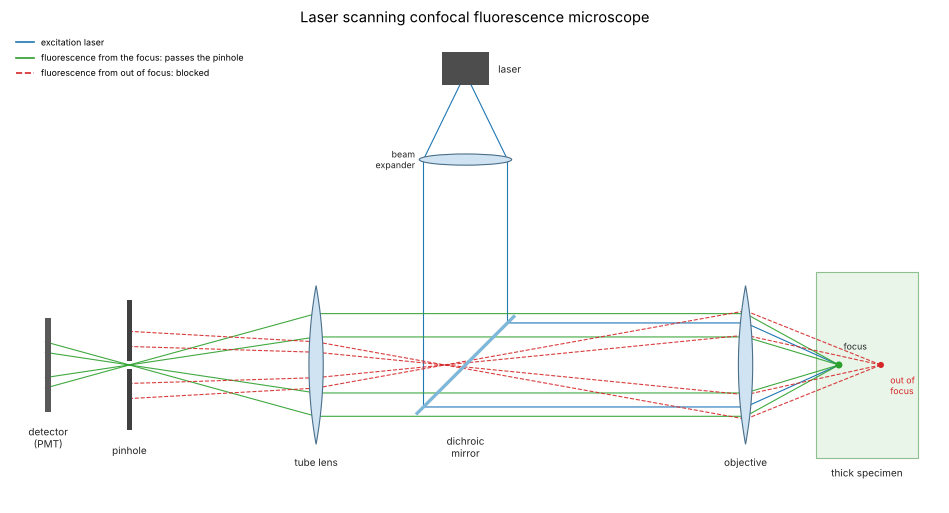

In [2]:
from pyoptics import sketch

fig, ax = plt.subplots(figsize=(12, 6.6))
sketch.confocal_microscope(ax, title="Laser scanning confocal fluorescence microscope")
plt.tight_layout()

## 1. The 3D wide field PSF

`psf_3d()` propagates the pupil to every plane with the exact
$k_z = \sqrt{n^2k_0^2 - k_\perp^2}$ (a scalar Debye integral); the
aplanatic option weights the pupil with $(n k_0/k_z)^{1/2}$, the amplitude
of an objective that obeys the sine condition. The classic estimates for
the widths (FWHM) of the intensity PSF are

$$\Delta x \approx 0.51\,\frac{\lambda}{\mathrm{NA}}, \qquad
  \Delta z \approx 0.88\,\frac{\lambda}{n - \sqrt{n^2 - \mathrm{NA}^2}} ,$$

the latter a non-paraxial version of $2n\lambda/\mathrm{NA}^2$. On the axis
the uniform pupil gives exactly
$|h(0,z)| = |\langle e^{i(k_z - nk_0)z}\rangle_\mathrm{pupil}|$, which
`mirror_response(z/2)` evaluates (a mirror doubles the defocus), and in
the paraxial limit $\mathrm{sinc}^2(u/4\pi)$ with $u = k_0\mathrm{NA}^2z/n$.

The right panel shows the key fact for sectioning: the **light in each
plane** $\int I\,dx\,dy$ is the same everywhere. Defocus spreads the
light but does not remove it, so a wide field microscope sees a uniform
fluorescent layer equally bright at any focus.

wide field FWHM: lateral 186 nm (0.51 lambda/NA = 189 nm), axial 503 nm (0.88 lambda/(n - sqrt(n^2 - NA^2)) = 491 nm)


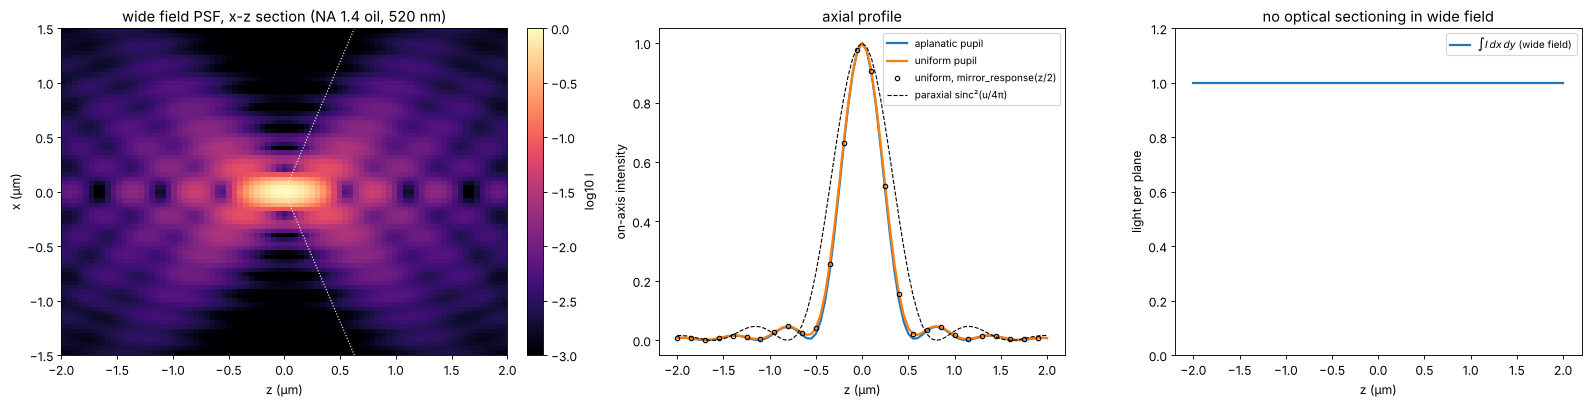

In [3]:
h_unif = mic.psf_3d(x, y, z, wl_em, NA, n=n_oil)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
ax = axes[0]
xz = I_wf[:, c, :].T
im = ax.imshow(np.log10(xz/xz.max() + 1e-4), extent=(z[0], z[-1], x[0], x[-1]), aspect="auto",
               cmap="magma", vmin=-3, vmax=0)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="log10 I")
ax.set_xlabel("z (µm)"); ax.set_ylabel("x (µm)"); ax.set_ylim(-1.5, 1.5)
ax.set_title(f"wide field PSF, x-z section (NA {NA} oil, {wl_em*1000:.0f} nm)")
ax.plot([0, 2], [0, 2*np.tan(alpha)], "w:", lw=1)
ax.plot([0, 2], [0, -2*np.tan(alpha)], "w:", lw=1)

ax = axes[1]
u = 2*np.pi/wl_em*NA**2*z/n_oil
ax.plot(z, I_wf[:, c, c], color="tab:blue", lw=2, label="aplanatic pupil")
ax.plot(z, np.abs(h_unif[:, c, c])**2, color="tab:orange", lw=2, label="uniform pupil")
ax.plot(z[::3], mic.mirror_response(z[::3]/2, wl_em, NA, n=n_oil), "ko", mfc="none", ms=4,
        label="uniform, mirror_response(z/2)")
ax.plot(z, np.sinc(u/(4*np.pi))**2, "k--", lw=1, label="paraxial sinc²(u/4π)")
ax.set_xlabel("z (µm)"); ax.set_ylabel("on-axis intensity"); ax.legend(fontsize=9)
ax.set_title("axial profile")

ax = axes[2]
E = np.sum(I_wf, axis=(1, 2))
ax.plot(z, E/E[iz0], lw=2, label=r"$\int I\,dx\,dy$ (wide field)")
ax.set_ylim(0, 1.2); ax.set_xlabel("z (µm)"); ax.set_ylabel("light per plane")
ax.set_title("no optical sectioning in wide field"); ax.legend(fontsize=9)
plt.tight_layout()

dx_wf, dz_wf = fwhm(x, I_wf[iz0, c]), fwhm(z, I_wf[:, c, c])
print(f"wide field FWHM: lateral {dx_wf*1000:.0f} nm (0.51 lambda/NA = {0.51*wl_em/NA*1000:.0f} nm), "
      f"axial {dz_wf*1000:.0f} nm (0.88 lambda/(n - sqrt(n^2 - NA^2)) = "
      f"{0.88*wl_em/(n_oil - np.sqrt(n_oil**2 - NA**2))*1000:.0f} nm)")

The aplanatic weighting puts more weight on the pupil edge and makes the
focus slightly narrower and the axial profile asymmetric; the uniform
pupil agrees with the exact on-axis integral, while the paraxial formula
overestimates the axial extent at this NA by about 40 %.

## 2. The confocal PSF

The laser spot excites a fluorophore at $\mathbf{r}$ with
$|h_\mathrm{exc}(\mathbf{r})|^2$. Its emitted light forms the spot
$|h_\mathrm{det}|^2$ in the image plane, centred at the (back projected)
position of the fluorophore, and the pinhole $D$ passes the fraction
$(|h_\mathrm{det}|^2 \otimes D)(\mathbf{r})$. Fluorescence is incoherent,
so the PSF of the scanned image is the product

$$\mathrm{PSF}_\mathrm{conf}(\mathbf{r}) = |h_\mathrm{exc}(\mathbf{r})|^2\,
  \big(|h_\mathrm{det}|^2 \otimes D\big)(\mathbf{r}) .$$

For a point pinhole it is $|h_\mathrm{exc}|^2|h_\mathrm{det}|^2$: for
equal wavelengths the square of the wide field PSF, $\sqrt{2}$ times
narrower for a Gaussian-like core (FWHM $\approx 0.37\lambda/\mathrm{NA}$
laterally, $0.64\lambda/(n - \sqrt{n^2 - \mathrm{NA}^2})$ axially), and the
side lobes are suppressed. Open pinholes approach the excitation PSF.

point pinhole: lateral 129 nm (0.37 lambda/NA = 133 nm), axial 351 nm (0.64 lambda/(n - sqrt(n^2 - NA^2)) = 346 nm)


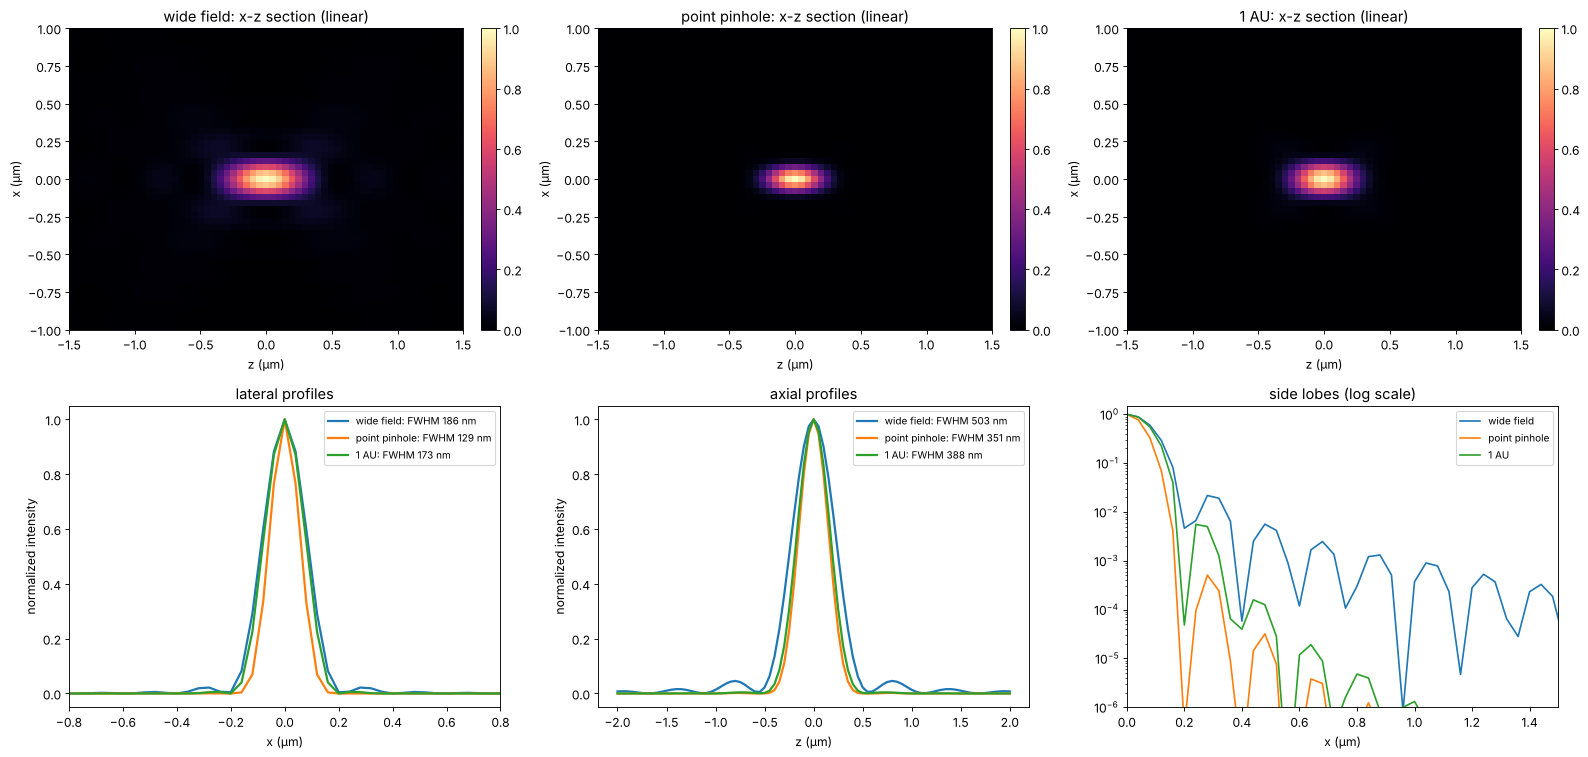

In [4]:
pinholes = {"point pinhole": None, "1 AU": AU}
psf_c = {name: mic.confocal_psf(h_exc, h_det, x, y, d) for name, d in pinholes.items()}
lam_mean = np.sqrt(wl_exc*wl_em)
fig, axes = plt.subplots(2, 3, figsize=(20, 9.6))
for j, (name, P) in enumerate([("wide field", I_wf)] + list(psf_c.items())):
    ax = axes[0, j]
    xz = P[:, c, :].T
    im = ax.imshow(xz/xz.max(), extent=(z[0], z[-1], x[0], x[-1]), aspect="auto", cmap="magma",
                   vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xlabel("z (µm)"); ax.set_ylabel("x (µm)"); ax.set_ylim(-1, 1); ax.set_xlim(-1.5, 1.5)
    ax.set_title(f"{name}: x-z section (linear)")
ax = axes[1, 0]
for name, P in [("wide field", I_wf)] + list(psf_c.items()):
    ax.plot(x, P[iz0, c]/P[iz0, c].max(), lw=2, label=f"{name}: FWHM {fwhm(x, P[iz0, c])*1000:.0f} nm")
ax.set_xlim(-0.8, 0.8); ax.set_xlabel("x (µm)"); ax.set_ylabel("normalized intensity")
ax.set_title("lateral profiles"); ax.legend(fontsize=9)
ax = axes[1, 1]
for name, P in [("wide field", I_wf)] + list(psf_c.items()):
    ax.plot(z, P[:, c, c]/P[:, c, c].max(), lw=2, label=f"{name}: FWHM {fwhm(z, P[:, c, c])*1000:.0f} nm")
ax.set_xlabel("z (µm)"); ax.set_ylabel("normalized intensity")
ax.set_title("axial profiles"); ax.legend(fontsize=9)
ax = axes[1, 2]
for name, P in [("wide field", I_wf)] + list(psf_c.items()):
    row = P[iz0, c]/P[iz0, c].max()
    ax.semilogy(x, row, lw=1.5, label=name)
ax.set_ylim(1e-6, 1.5); ax.set_xlim(0, 1.5); ax.set_xlabel("x (µm)")
ax.set_title("side lobes (log scale)"); ax.legend(fontsize=9)
plt.tight_layout()
print(f"point pinhole: lateral {fwhm(x, psf_c['point pinhole'][iz0, c])*1000:.0f} nm "
      f"(0.37 lambda/NA = {0.37*lam_mean/NA*1000:.0f} nm), axial "
      f"{fwhm(z, psf_c['point pinhole'][:, c, c])*1000:.0f} nm "
      f"(0.64 lambda/(n - sqrt(n^2 - NA^2)) = {0.64*lam_mean/(n_oil - np.sqrt(n_oil**2 - NA**2))*1000:.0f} nm)")

(The estimates use the geometric mean of the two wavelengths.) The point
pinhole is a theoretical limit: it collects no light. In practice the
pinhole is set to about 1 AU, where the lateral resolution is close to
wide field and the gain of confocal microscopy lies almost entirely in
the sectioning.

## 3. The pinhole: resolution, sectioning and signal

How large may the pinhole be? The plot follows the lateral and axial FWHM
of the PSF of a point and the detected signal from a point in focus, for
pinholes from 0 to 3 AU. The full lateral gain needs pinholes below about
0.25 AU, which pass only a quarter of the light; by 1 AU it is mostly
gone. The axial width of the PSF degrades more slowly. Beyond 1 AU the
signal grows only slowly (the paraxial Airy disk holds 84 % of the light,
the aplanatic high NA PSF here somewhat less), so 1 AU is the usual
compromise.

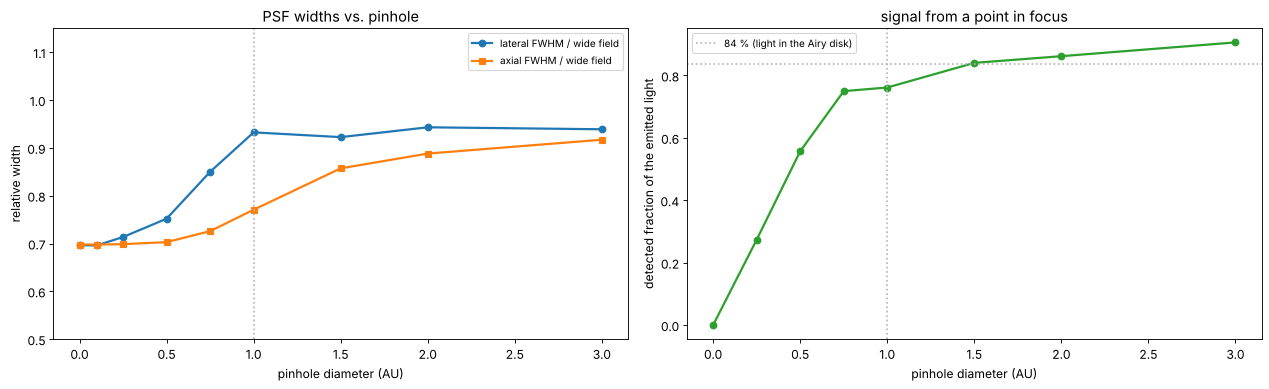

In [5]:
d_au = np.array([0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0])
lat, ax_w, sig = [], [], []
for d in d_au:
    P = mic.confocal_psf(h_exc, h_det, x, y, d*AU if d > 0 else None)
    lat.append(fwhm(x, P[iz0, c]))
    ax_w.append(fwhm(z, P[:, c, c]))
    sig.append(P[iz0, c, c])
lat, ax_w, sig = map(np.array, (lat, ax_w, sig))
# signal relative to the full Airy pattern (an infinitely large pinhole)
sig_rel = sig/(np.abs(h_exc[iz0, c, c])**2*np.sum(np.abs(h_det[iz0])**2))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.plot(d_au, lat/dx_wf, "o-", lw=2, label="lateral FWHM / wide field")
ax.plot(d_au, ax_w/dz_wf, "s-", lw=2, label="axial FWHM / wide field")
ax.axvline(1.0, color="0.7", ls=":")
ax.set_xlabel("pinhole diameter (AU)"); ax.set_ylabel("relative width")
ax.set_title("PSF widths vs. pinhole"); ax.legend(fontsize=9); ax.set_ylim(0.5, 1.15)
ax = axes[1]
# a point pinhole collects nothing; pinholes below one pixel are not resolved on this grid
ok = d_au >= 0.25
ax.plot(np.r_[0, d_au[ok]], np.r_[0, sig_rel[ok]], "o-", lw=2, color="tab:green")
ax.axhline(0.838, color="0.7", ls=":", label="84 % (light in the Airy disk)")
ax.axvline(1.0, color="0.7", ls=":")
ax.set_xlabel("pinhole diameter (AU)"); ax.set_ylabel("detected fraction of the emitted light")
ax.set_title("signal from a point in focus"); ax.legend(fontsize=9)
plt.tight_layout()

The axial FWHM of the PSF of a point (a bead) stays within the wide field
value even for large pinholes, because the excitation spot alone is
already confined; what changes dramatically is the response to extended
objects, the subject of the next section.

## 4. Optical sectioning

The standard test of sectioning is a thin uniform fluorescent layer moved
through the focus. Its signal is the integral of the PSF over each plane
(`plane_response()`): constant for wide field, falling off for confocal.
Far from focus the defocused detection spot of radius $\approx z\tan\alpha$
overfills the pinhole, so the detected fraction falls like
$1/z^2$; the excitation light per plane is constant. Here a larger window
(20 µm) is used so that the defocused spots do not wrap around, and the
planes are computed one by one.

A **reflection** confocal microscope seen by a plane mirror (point
pinhole) is coherent: the reflected field is the pupil with twice the
defocus, and the detected intensity is
$|\langle e^{2i(k_z - nk_0)z}\rangle|^2$ (`mirror_response()`), in the
paraxial limit $\mathrm{sinc}^2(u/2\pi)$, the first zero at
$z = n\lambda/\mathrm{NA}^2$. This is the principle of confocal
profilometers for surface topography.

confocal 0.5 AU: plane response FWHM 0.39 um
confocal 1 AU: plane response FWHM 0.50 um
confocal 2 AU: plane response FWHM 0.81 um


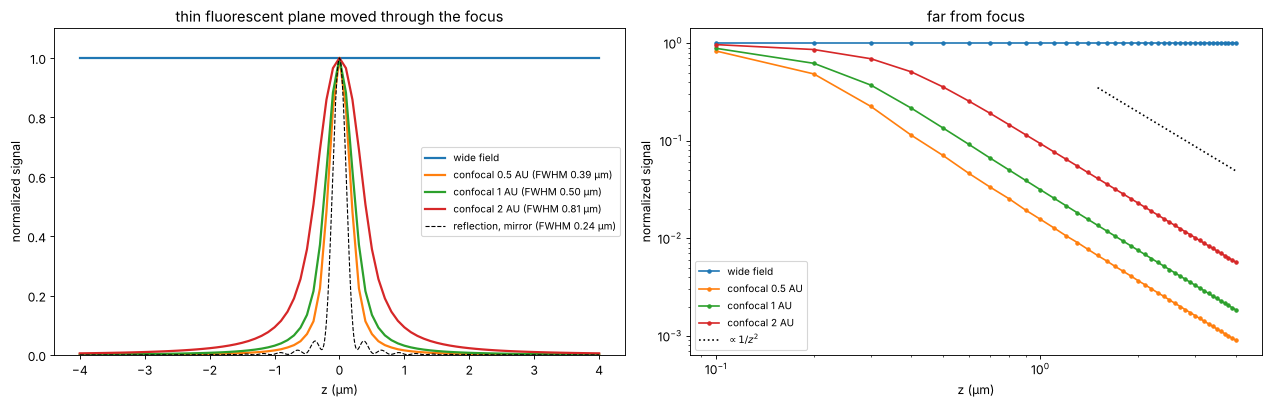

In [6]:
N2, dx2 = 512, 0.04
L2 = N2*dx2
x2, y2, _, _ = grid2d(-L2/2, L2/2, -L2/2, L2/2, N2)
z2 = np.linspace(-4, 4, 81)
resp = {"wide field": [], "confocal 0.5 AU": [], "confocal 1 AU": [], "confocal 2 AU": []}
for zi in z2:
    he = mic.psf_3d(x2, y2, zi, wl_exc, NA, n=n_oil, apodization="aplanatic")
    hd = mic.psf_3d(x2, y2, zi, wl_em, NA, n=n_oil, apodization="aplanatic")
    resp["wide field"].append(np.sum(np.abs(hd)**2))
    for name, d in [("confocal 0.5 AU", 0.5), ("confocal 1 AU", 1.0), ("confocal 2 AU", 2.0)]:
        resp[name].append(np.sum(mic.confocal_psf(he, hd, x2, y2, d*AU)))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
widths = {}
for name, r in resp.items():
    r = np.array(r)/np.max(r)
    if name != "wide field":
        widths[name] = fwhm(z2, r)
    ax.plot(z2, r, lw=2, label=name + (f" (FWHM {widths[name]:.2f} µm)" if name in widths else ""))
zm = np.linspace(-4, 4, 801)
I_m = mic.mirror_response(zm, wl_exc, NA, n=n_oil)
ax.plot(zm, I_m, "k--", lw=1, label=f"reflection, mirror (FWHM {fwhm(zm, I_m):.2f} µm)")
ax.set_xlabel("z (µm)"); ax.set_ylabel("normalized signal"); ax.set_ylim(0, 1.1)
ax.set_title("thin fluorescent plane moved through the focus"); ax.legend(fontsize=9)
ax = axes[1]
for name, r in resp.items():
    r = np.array(r)/np.max(r)
    sel = z2 > 0
    ax.loglog(z2[sel], r[sel], "o-", ms=3, lw=1.5, label=name)
zz = np.array([1.5, 4])
ax.loglog(zz, 0.35*(zz/1.5)**-2, "k:", label=r"$\propto 1/z^2$")
ax.set_xlabel("z (µm)"); ax.set_ylabel("normalized signal")
ax.set_title("far from focus"); ax.legend(fontsize=9)
plt.tight_layout()
for name, w in widths.items():
    print(f"{name}: plane response FWHM {w:.2f} um")

The sectioning width grows with the pinhole: about 0.5 µm at 1 AU for this
objective, 1.6 times that at 2 AU. The reflection response with its point
pinhole is narrower still (0.24 µm, while the paraxial
$0.89\,n\lambda/\mathrm{NA}^2$ would give 0.34 µm), and its side lobes are
the zeros of the coherent sinc.

## 5. An x-z section through a thick sample

The final test: a fluorescent "cell" with a membrane, a nucleus envelope
and filaments, all extended along $y$ (so that the 3D convolution
reduces to a 2D convolution in $x$ and $z$ with the PSF integrated over
$y$). The wide field image (an x-z stack of focus positions) drowns the
section in out-of-focus light and stretches everything along $z$; the
confocal image at 1 AU shows a clean section. The PSFs are computed on a
10 × 10 µm x-z window and the sample is placed in its centre.

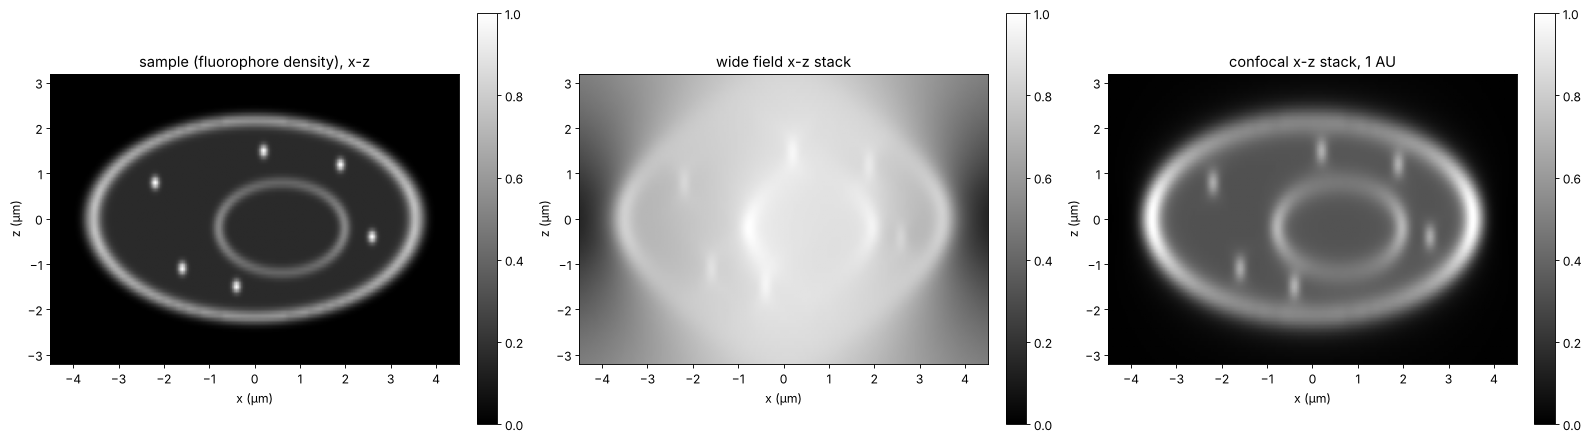

In [7]:
z3 = np.arange(-64, 64)*0.08            # 10.24 um, same span as x
psf_wf_xz, psf_cf_xz = [], []
for zi in z3:
    he = mic.psf_3d(x, y, zi, wl_exc, NA, n=n_oil, apodization="aplanatic")
    hd = mic.psf_3d(x, y, zi, wl_em, NA, n=n_oil, apodization="aplanatic")
    psf_wf_xz.append(np.sum(np.abs(hd)**2, axis=0))
    psf_cf_xz.append(np.sum(mic.confocal_psf(he, hd, x, y, AU), axis=0))
psf_wf_xz, psf_cf_xz = np.array(psf_wf_xz), np.array(psf_cf_xz)   # (z, x)

ZZ, XX = np.meshgrid(z3, x, indexing="ij")
r_ell = np.hypot(XX/3.6, ZZ/2.2)
# thin shells as smooth rings, thicker than the z sampling of 0.08 um
sample = 1.0*np.exp(-((r_ell - 1)/0.05)**2)                                        # membrane
sample += 0.6*np.exp(-((np.hypot((XX - 0.6)/1.4, (ZZ + 0.2)/1.0) - 1)/0.08)**2)   # nuclear envelope
for x0, z0 in [(-2.2, 0.8), (-1.6, -1.1), (1.9, 1.2), (2.6, -0.4), (0.2, 1.5), (-0.4, -1.5)]:
    sample += 3*np.exp(-((XX - x0)**2 + (ZZ - z0)**2)/(2*0.05**2))           # filaments along y
sample += 0.25*(r_ell < 1)                                  # cytoplasmic background
sample = gaussian_filter(sample, 1.0)                       # no stair steps from the grid


def image(psf):
    return np.real(np.fft.ifft2(np.fft.fft2(sample)*np.fft.fft2(np.fft.ifftshift(psf/psf.sum()))))


img_wf, img_cf = image(psf_wf_xz), image(psf_cf_xz)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.6))
ext = (x[0], x[-1], z3[0], z3[-1])
for ax, img, title in [(axes[0], sample, "sample (fluorophore density), x-z"),
                       (axes[1], img_wf, "wide field x-z stack"),
                       (axes[2], img_cf, "confocal x-z stack, 1 AU")]:
    im = ax.imshow(img/img.max(), extent=ext, cmap="gray", vmin=0, vmax=1, aspect="equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-3.2, 3.2)
    ax.set_xlabel("x (µm)"); ax.set_ylabel("z (µm)"); ax.set_title(title)
plt.tight_layout()

## Summary

- The wide field PSF spreads the light of each plane over a growing disk
  but keeps it: a uniform layer looks the same at every focus, there is
  no optical sectioning.
- The confocal PSF is the product of excitation PSF and detection PSF
  convolved with the pinhole (`confocal_psf()`). A point pinhole narrows
  the PSF by about $\sqrt{2}$ and suppresses the side lobes, but collects no
  light; at the usual 1 AU the lateral resolution is close to wide field.
- The real gain is **optical sectioning**: the signal of a fluorescent
  plane falls off as $1/z^2$ (`plane_response()`), with a width of about
  0.5 µm at 1 AU and NA 1.4, growing with the pinhole above 1 AU.
- A reflection confocal (coherent, mirror) gives the response
  $|\langle e^{2i(k_z - nk_0)z}\rangle|^2$ (`mirror_response()`), with the
  paraxial width $0.89\,n\lambda/\mathrm{NA}^2$ (narrower at high NA).

Image scanning microscopy (Airyscan and similar) replaces the pinhole by a
small detector array and reassigns the pixels to recover the $\sqrt{2}$
without losing light; it builds on exactly the PSF product computed here.

In [8]:
print(f"run time {time.time() - t_start:.0f} s")

run time 31 s


## References

- M. Minsky, "Microscopy apparatus", US patent 3,013,467 (1961, filed 1957); M. Minsky, "Memoir on inventing the confocal scanning microscope", Scanning 10, 128-138 (1988).
- T. Wilson and C. Sheppard, *Theory and Practice of Scanning Optical Microscopy*, Academic Press (1984).
- C. J. R. Sheppard and T. Wilson, "Depth of field in the scanning microscope", Opt. Lett. 3, 115-117 (1978).
- T. Wilson (ed.), *Confocal Microscopy*, Academic Press (1990).
- J. B. Pawley (ed.), *Handbook of Biological Confocal Microscopy*, 3rd ed., Springer (2006).
- B. Richards and E. Wolf, "Electromagnetic diffraction in optical systems II. Structure of the image field in an aplanatic system", Proc. R. Soc. Lond. A 253, 358-379 (1959).
- C. B. Müller and J. Enderlein, "Image scanning microscopy", Phys. Rev. Lett. 104, 198101 (2010).
- J. Mertz, *Introduction to Optical Microscopy*, 2nd ed., Cambridge University Press (2019).